<a href="https://colab.research.google.com/github/Cheikhcisse1/projet_FN/blob/main/SerieTemporelle_corrige.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Analyse et prévision de séries temporelles — version corrigée

**Démarche :** exploration → stationnarité → identification (ACF/PACF) → modélisation SARIMA → validation (tests paramétriques) → évaluation sur jeu de test → prévision.

**Corrections par rapport à la version précédente**
1. La classe `SerieTemporelle` est réorganisée (le bloc `set_index` mal placé est remis dans `__init__`).
2. L'ACF/PACF après stationnarisation porte bien sur la **série stationnaire** (avant : sur la série brute).
3. Plus de **double différenciation** : le modèle est entraîné sur `log(série)` et c'est lui qui applique `d=1` et `D=1`.
4. Ajout d'un **jeu de test** (24 derniers mois) et de métriques (MAE, RMSE, MAPE).
5. Les prévisions sont **remises à l'échelle d'origine** (`exp`) avec un **intervalle de confiance à 95 %**.
6. Ajout des **tests paramétriques** : significativité des coefficients, Ljung-Box, normalité, ARCH.
7. Le modèle manuel utilise `statsmodels.SARIMAX` (intervalles de confiance et résumé complets) ; `pmdarima.auto_arima` sert de comparaison.

In [ ]:
# Colab : décommenter si pmdarima n'est pas installé
# %pip install -q pmdarima

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import boxcox

from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from pmdarima import auto_arima

plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.grid"] = True

## 1. Classe `SerieTemporelle` : exploration et stationnarité

In [ ]:
class SerieTemporelle:
    """Exploration, transformation et tests de stationnarité d'une série temporelle."""

    def __init__(self, donnee, colonne, date="date"):
        self.donnee = donnee.copy()
        self.colonne = colonne
        self.date = date

        if self.colonne not in self.donnee.columns:
            raise ValueError(
                f"La colonne '{self.colonne}' n'existe pas. "
                f"Colonnes disponibles : {self.donnee.columns.tolist()}"
            )

        # Cas 1 : les dates sont déjà dans l'index
        if isinstance(self.donnee.index, pd.DatetimeIndex):
            self.donnee.index.name = self.date
        # Cas 2 : les dates sont dans une colonne
        elif self.date in self.donnee.columns:
            self.donnee[self.date] = pd.to_datetime(self.donnee[self.date], errors="coerce")
            self.donnee = self.donnee.dropna(subset=[self.date]).set_index(self.date)
        else:
            raise ValueError(f"La date '{self.date}' est absente des colonnes et de l'index.")

        self.donnee = self.donnee.sort_index()
        self.donnee[self.colonne] = pd.to_numeric(self.donnee[self.colonne], errors="coerce")

    # ---------- 1. Description ----------
    def description(self):
        print("Dimensions :", self.donnee.shape)
        print("Période    :", self.donnee.index.min().date(), "->", self.donnee.index.max().date())
        print("Valeurs manquantes :", self.donnee[self.colonne].isnull().sum())
        print("Dates en double    :", self.donnee.index.duplicated().sum())
        display(self.donnee[self.colonne].describe().to_frame().T.round(2))

    # ---------- 2. Visualisation ----------
    def visualisation(self, colonne=None, titre=None):
        colonne = colonne or self.colonne
        plt.figure()
        plt.plot(self.donnee.index, self.donnee[colonne], label=colonne)
        plt.title(titre or f"Évolution de {colonne}")
        plt.xlabel("Date"); plt.ylabel(colonne); plt.legend()
        plt.tight_layout(); plt.show()

    # ---------- 3. Valeurs manquantes ----------
    def traitement_valeurs_manquantes(self, methode="interpolate"):
        s = self.donnee[self.colonne]
        print("Valeurs manquantes avant :", s.isnull().sum())
        if methode == "interpolate":
            self.donnee[self.colonne] = s.interpolate(method="time")
        elif methode == "mean":
            self.donnee[self.colonne] = s.fillna(s.mean())
        elif methode == "median":
            self.donnee[self.colonne] = s.fillna(s.median())
        elif methode == "ffill":
            self.donnee[self.colonne] = s.ffill()
        elif methode == "bfill":
            self.donnee[self.colonne] = s.bfill()
        elif methode == "drop":
            self.donnee = self.donnee.dropna(subset=[self.colonne])
        else:
            raise ValueError("Méthode inconnue.")
        print("Valeurs manquantes après :", self.donnee[self.colonne].isnull().sum())
        return self.donnee

    # ---------- 4. Fréquence de l'index ----------
    def preparer_index(self, frequence=None):
        if self.donnee.index.has_duplicates:
            raise ValueError("Dates en double : agrégez-les avant de continuer.")
        frequence = frequence or pd.infer_freq(self.donnee.index)
        if frequence is None:
            print("Fréquence non détectée : précisez-la (ex. 'MS').")
        else:
            self.donnee = self.donnee.asfreq(frequence)
            print("Fréquence :", frequence)
        return self.donnee

    # ---------- 5. Décomposition ----------
    def decomposition(self, periode=12, modele="additive"):
        res = seasonal_decompose(self.donnee[self.colonne].dropna(), model=modele, period=periode)
        fig = res.plot()
        fig.set_size_inches(12, 8)
        fig.suptitle(f"Décomposition {modele} de {self.colonne}", y=1.01)
        plt.tight_layout(); plt.show()
        return res

    # ---------- 6-7. Tests de stationnarité ----------
    def ADF_test(self, colonne=None, alpha=0.05, verbose=True):
        serie = self.donnee[colonne or self.colonne].dropna()
        stat, p, *_ = adfuller(serie)
        if verbose:
            print(f"ADF  : stat = {stat:.3f} | p-value = {p:.4f} ->",
                  "stationnaire" if p < alpha else "NON stationnaire")
        return p

    def KPSS_test(self, colonne=None, alpha=0.05, verbose=True):
        serie = self.donnee[colonne or self.colonne].dropna()
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            stat, p, *_ = kpss(serie, regression="c", nlags="auto")
        if verbose:
            print(f"KPSS : stat = {stat:.3f} | p-value = {p:.4f} ->",
                  "stationnaire" if p > alpha else "NON stationnaire")
        return p

    def stationnarite(self, colonne=None):
        """ADF (H0 : non stationnaire) + KPSS (H0 : stationnaire). Conclusion si les deux s'accordent."""
        colonne = colonne or self.colonne
        print(f"--- Stationnarité de '{colonne}' ---")
        p_adf, p_kpss = self.ADF_test(colonne), self.KPSS_test(colonne)
        if p_adf < 0.05 and p_kpss > 0.05:
            print("=> Les deux tests concluent : série STATIONNAIRE")
        elif p_adf > 0.05 and p_kpss < 0.05:
            print("=> Les deux tests concluent : série NON stationnaire")
        else:
            print("=> Tests en désaccord : stationnarité douteuse (tendance ou différenciation excessive)")

    # ---------- 8. ACF / PACF ----------
    def courbe_ACF_PACF(self, lags=36, colonne=None):
        colonne = colonne or self.colonne
        serie = self.donnee[colonne].dropna()
        lags = min(lags, len(serie) // 2 - 1)
        fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
        plot_acf(serie, lags=lags, ax=axes[0]); axes[0].set_title(f"ACF — {colonne}")
        plot_pacf(serie, lags=lags, ax=axes[1], method="ywm"); axes[1].set_title(f"PACF — {colonne}")
        plt.tight_layout(); plt.show()

    # ---------- 9-11. Transformations ----------
    def logarithme(self):
        if (self.donnee[self.colonne].dropna() <= 0).any():
            raise ValueError("Le log nécessite des valeurs strictement positives.")
        nom = self.colonne + "_log"
        self.donnee[nom] = np.log(self.donnee[self.colonne])
        return self.donnee[nom]

    def boxcox(self):
        valeurs = self.donnee[self.colonne].dropna()
        if (valeurs <= 0).any():
            raise ValueError("Box-Cox nécessite des valeurs strictement positives.")
        transf, lam = boxcox(valeurs)
        nom = self.colonne + "_boxcox"
        self.donnee.loc[valeurs.index, nom] = transf
        print(f"Lambda optimal : {lam:.3f}  (proche de 0 => le log suffit)")
        return self.donnee[nom], lam

    def differenciation(self, colonne=None, ordre=1, periode=None):
        """ordre : différenciation simple ; periode : différenciation saisonnière (ex. 12)."""
        colonne = colonne or self.colonne
        s = self.donnee[colonne]
        for _ in range(ordre):
            s = s.diff()
        if periode:
            s = s.diff(periode)
        nom = f"{colonne}_d{ordre}" + (f"_D{periode}" if periode else "")
        self.donnee[nom] = s
        return nom

    def rendre_stationnaire(self, periode=12, log=True):
        """log (optionnel) + différenciation simple + différenciation saisonnière."""
        base = self.colonne
        if log:
            self.logarithme(); base = self.colonne + "_log"
        nom = self.differenciation(colonne=base, ordre=1, periode=periode)
        self.donnee[self.colonne + "_stationnaire"] = self.donnee[nom]
        self.visualisation(self.colonne + "_stationnaire",
                           "Série après log + différenciation simple + saisonnière")
        self.stationnarite(self.colonne + "_stationnaire")
        return self.colonne + "_stationnaire"

## 2. Classe `Sarimax_model` : modélisation, validation, prévision

Principe : on modélise **log(série)** (le log stabilise la variance d'une série multiplicative) et on laisse le modèle faire la différenciation (`d`, `D`). Les prévisions sont ensuite remises à l'échelle d'origine avec `exp`.

In [ ]:
class Sarimax_model(SerieTemporelle):

    def __init__(self, donnee, colonne, date="date", s=12, log=True, frequence="MS"):
        super().__init__(donnee, colonne=colonne, date=date)
        self.preparer_index(frequence)
        self.s, self.log = s, log
        self.modeles = {}      # nom -> résultat statsmodels
        self.previsions = {}   # nom -> DataFrame (prevision, borne_inf, borne_sup)

    # ---------- transformations ----------
    def _y(self, serie):
        return np.log(serie) if self.log else serie

    def _inv(self, x):
        return np.exp(x) if self.log else x

    # ---------- découpage ----------
    def decouper(self, n_test=24):
        serie = self.donnee[self.colonne].dropna()
        self.train, self.test = serie.iloc[:-n_test], serie.iloc[-n_test:]
        print(f"Entraînement : {self.train.index[0].date()} -> {self.train.index[-1].date()} ({len(self.train)} obs.)")
        print(f"Test         : {self.test.index[0].date()} -> {self.test.index[-1].date()} ({len(self.test)} obs.)")

    # ---------- entraînement ----------
    def entrainement_sarimax(self, order, seasonal_order, nom=None, serie=None):
        serie = self.train if serie is None else serie
        nom = nom or f"SARIMA{order}{seasonal_order}"
        res = SARIMAX(self._y(serie), order=order, seasonal_order=seasonal_order).fit(disp=False)
        self.modeles[nom] = res
        print(f"{nom} entraîné | AIC = {res.aic:.2f} | BIC = {res.bic:.2f}")
        return nom

    def entrainement_autoarima(self, trace=False):
        auto = auto_arima(self._y(self.train), seasonal=True, m=self.s,
                          stepwise=True, trace=trace, suppress_warnings=True,
                          error_action="ignore", information_criterion="aic")
        print("Meilleur modèle trouvé par auto_arima :", auto.order, auto.seasonal_order)
        return self.entrainement_sarimax(auto.order, auto.seasonal_order,
                                         nom=f"auto {auto.order}{auto.seasonal_order}")

    # ---------- validation ----------
    def residus(self, nom):
        res = self.modeles[nom]
        d, D = res.model.order[1], res.model.seasonal_order[1]
        return pd.Series(res.resid).iloc[d + D * self.s:]   # on retire la période d'initialisation

    def diagnostic(self, nom):
        print(self.modeles[nom].summary().tables[1])
        self.modeles[nom].plot_diagnostics(figsize=(14, 9))
        plt.suptitle(f"Diagnostic des résidus — {nom}", y=1.01)
        plt.tight_layout(); plt.show()

    def tests_parametriques(self, nom, alpha=0.05, lags=12):
        res, resid = self.modeles[nom], self.residus(nom)
        ok = lambda c: "OK" if c else "ÉCHEC"
        print(f"=============== TESTS — {nom} ===============")
        tab = pd.DataFrame({"coef": res.params, "z": res.tvalues, "p-value": res.pvalues})
        tab = tab.drop(index="sigma2", errors="ignore")
        tab["significatif"] = np.where(tab["p-value"] < alpha, "oui", "NON")
        print("1. Significativité des coefficients (H0 : coef = 0, on veut p < 0.05)")
        print(tab.round(4).to_string(), "\n")

        p = stats.ttest_1samp(resid, 0).pvalue
        print(f"2. Moyenne des résidus = 0 (Student)   p = {p:.4f}  {ok(p > alpha)}")
        p = acorr_ljungbox(resid, lags=[lags], return_df=True)["lb_pvalue"].iloc[0]
        print(f"3. Bruit blanc (Ljung-Box, {lags} retards)  p = {p:.4f}  {ok(p > alpha)}")
        p1, p2 = stats.shapiro(resid).pvalue, stats.jarque_bera(resid).pvalue
        print(f"4. Normalité (Shapiro / Jarque-Bera)   p = {p1:.4f} / {p2:.4f}  {ok(min(p1, p2) > alpha)}")
        p = het_arch(resid, nlags=lags)[1]
        print(f"5. Variance constante (ARCH d'Engle)   p = {p:.4f}  {ok(p > alpha)}")
        return tab

    # ---------- prévision ----------
    def prediction(self, nom, horizon=None):
        horizon = horizon or len(self.test)
        f = self.modeles[nom].get_forecast(horizon)
        ci = f.conf_int(alpha=0.05)
        prev = pd.DataFrame({"prevision": self._inv(f.predicted_mean),
                             "borne_inf": self._inv(ci.iloc[:, 0]),
                             "borne_sup": self._inv(ci.iloc[:, 1])})
        self.previsions[nom] = prev
        return prev

    def evaluation(self):
        lignes = []
        for nom, prev in self.previsions.items():
            reel = self.test.reindex(prev.index).dropna()
            if reel.empty:
                continue
            e = reel - prev.loc[reel.index, "prevision"]
            lignes.append({"modèle": nom, "AIC": round(self.modeles[nom].aic, 2),
                           "MAE": e.abs().mean(), "RMSE": np.sqrt((e ** 2).mean()),
                           "MAPE (%)": (e.abs() / reel).mean() * 100})
        return pd.DataFrame(lignes).set_index("modèle").round(2)

    def visualisation_prediction(self, noms=None, titre="Prévisions"):
        noms = noms or list(self.previsions)
        plt.figure(figsize=(12, 5))
        plt.plot(self.donnee[self.colonne], color="tab:blue", label="Données réelles")
        if hasattr(self, "test"):
            plt.axvline(self.test.index[0], color="grey", ls="--", lw=1)
        for nom, couleur in zip(noms, ["red", "green", "purple"]):
            p = self.previsions[nom]
            plt.plot(p["prevision"], color=couleur, label=nom)
            plt.fill_between(p.index, p["borne_inf"], p["borne_sup"], color=couleur, alpha=0.12)
        plt.title(titre); plt.ylabel(self.colonne); plt.legend()
        plt.tight_layout(); plt.show()

## 3. Application : AirPassengers (passagers aériens mensuels, 1949-1960)

Fréquence : MS
Dimensions : (144, 1)
Période    : 1949-01-01 -> 1960-12-01
Valeurs manquantes : 0
Dates en double    : 0


,count,mean,std,min,25%,50%,75%,max
passagers,144.0,280.3,119.97,104.0,180.0,265.5,360.5,622.0


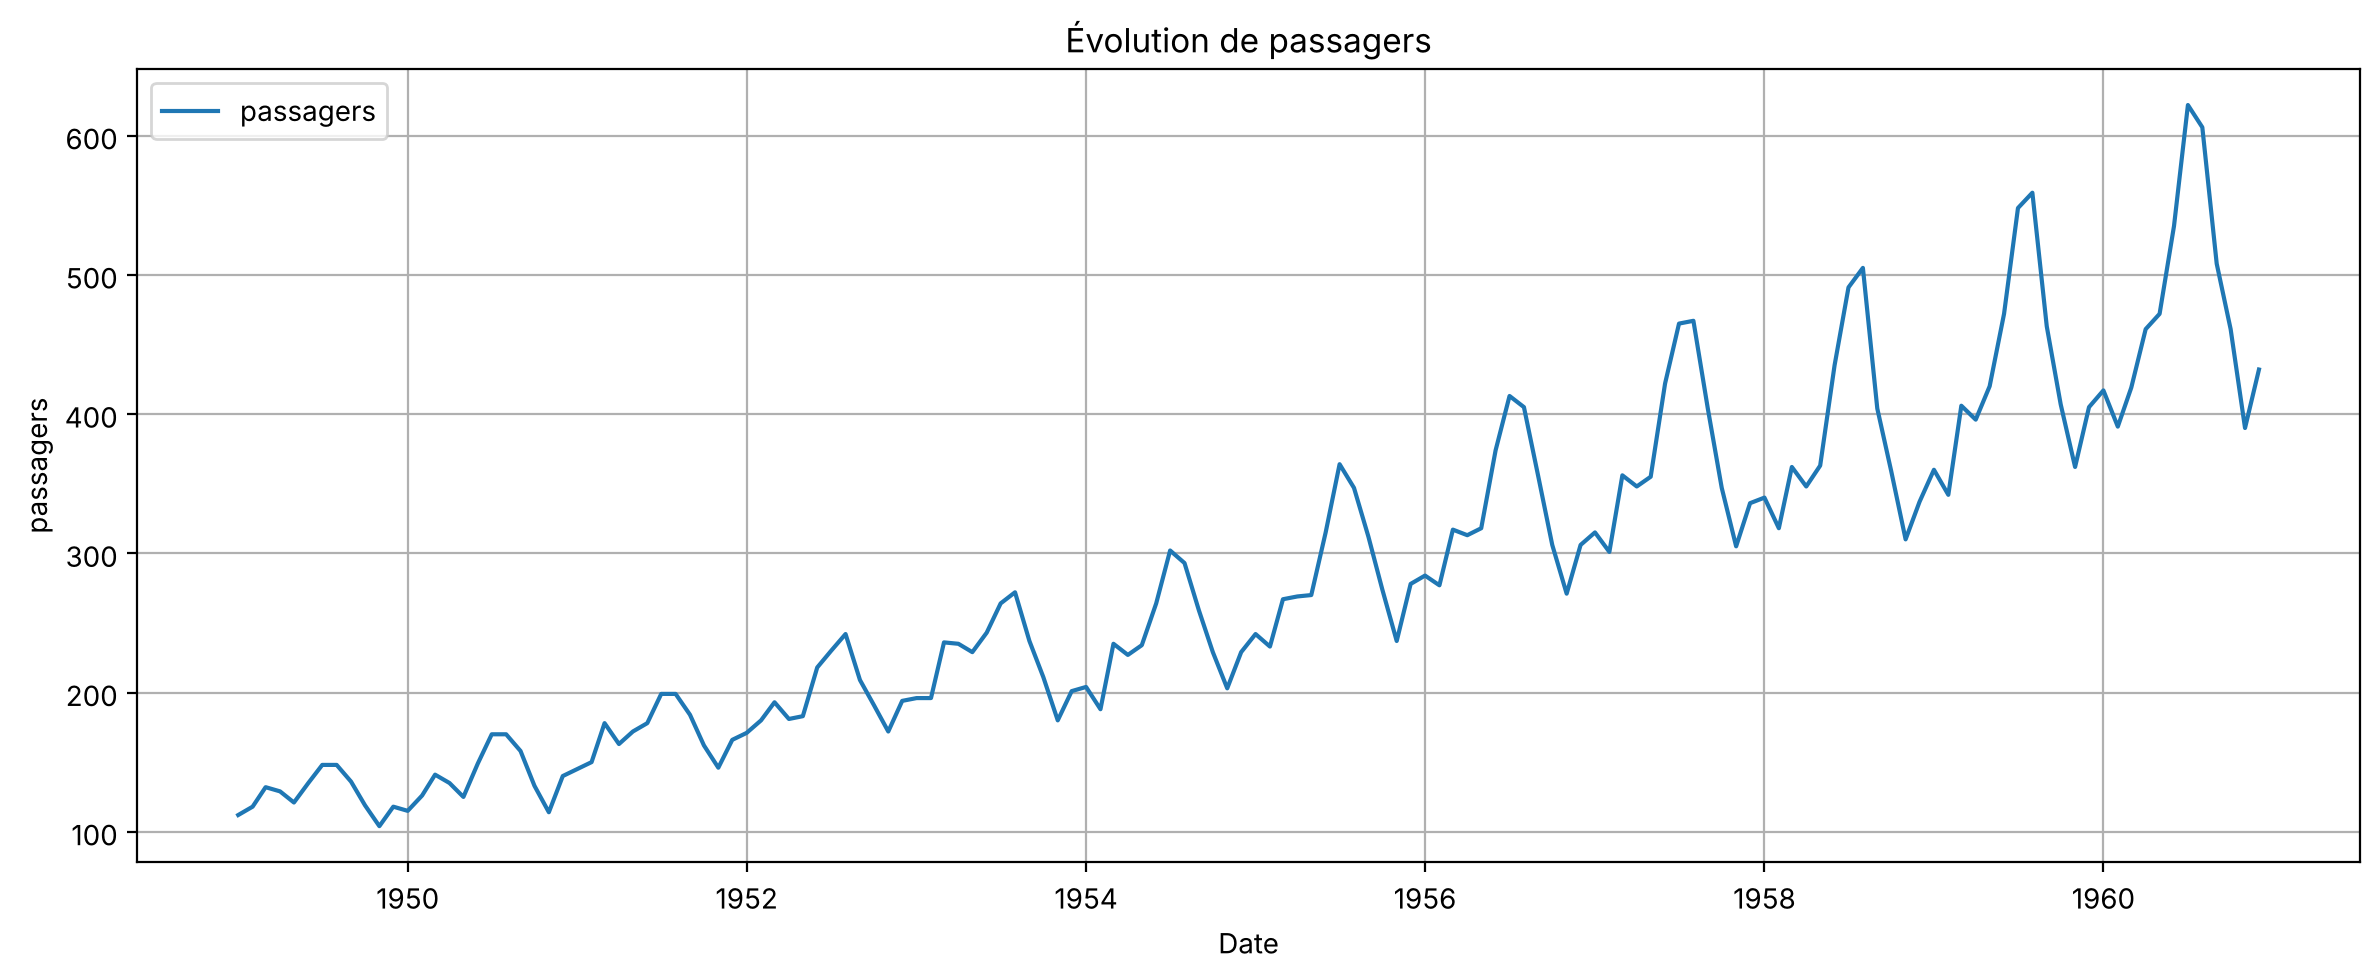

In [ ]:
try:
    import statsmodels.api as sm
    valeurs = sm.datasets.get_rdataset("AirPassengers", "datasets").data["value"].values
except Exception:  # pas d'accès Internet : données intégrées
    valeurs = [112,118,132,129,121,135,148,148,136,119,104,118,115,126,141,135,125,149,170,170,158,133,114,140,
               145,150,178,163,172,178,199,199,184,162,146,166,171,180,193,181,183,218,230,242,209,191,172,194,
               196,196,236,235,229,243,264,272,237,211,180,201,204,188,235,227,234,264,302,293,259,229,203,229,
               242,233,267,269,270,315,364,347,312,274,237,278,284,277,317,313,318,374,413,405,355,306,271,306,
               315,301,356,348,355,422,465,467,404,347,305,336,340,318,362,348,363,435,491,505,404,359,310,337,
               360,342,406,396,420,472,548,559,463,407,362,405,417,391,419,461,472,535,622,606,508,461,390,432]

data_df = pd.DataFrame({"date": pd.date_range("1949-01", periods=len(valeurs), freq="MS"),
                        "passagers": valeurs})

air = Sarimax_model(data_df, colonne="passagers", date="date", s=12, log=True)
air.description()
air.visualisation()

**Lecture :** tendance croissante + pic chaque été (saisonnalité de 12 mois) + amplitude des vagues qui **augmente** avec le niveau → série **multiplicative**, d'où l'usage du log.

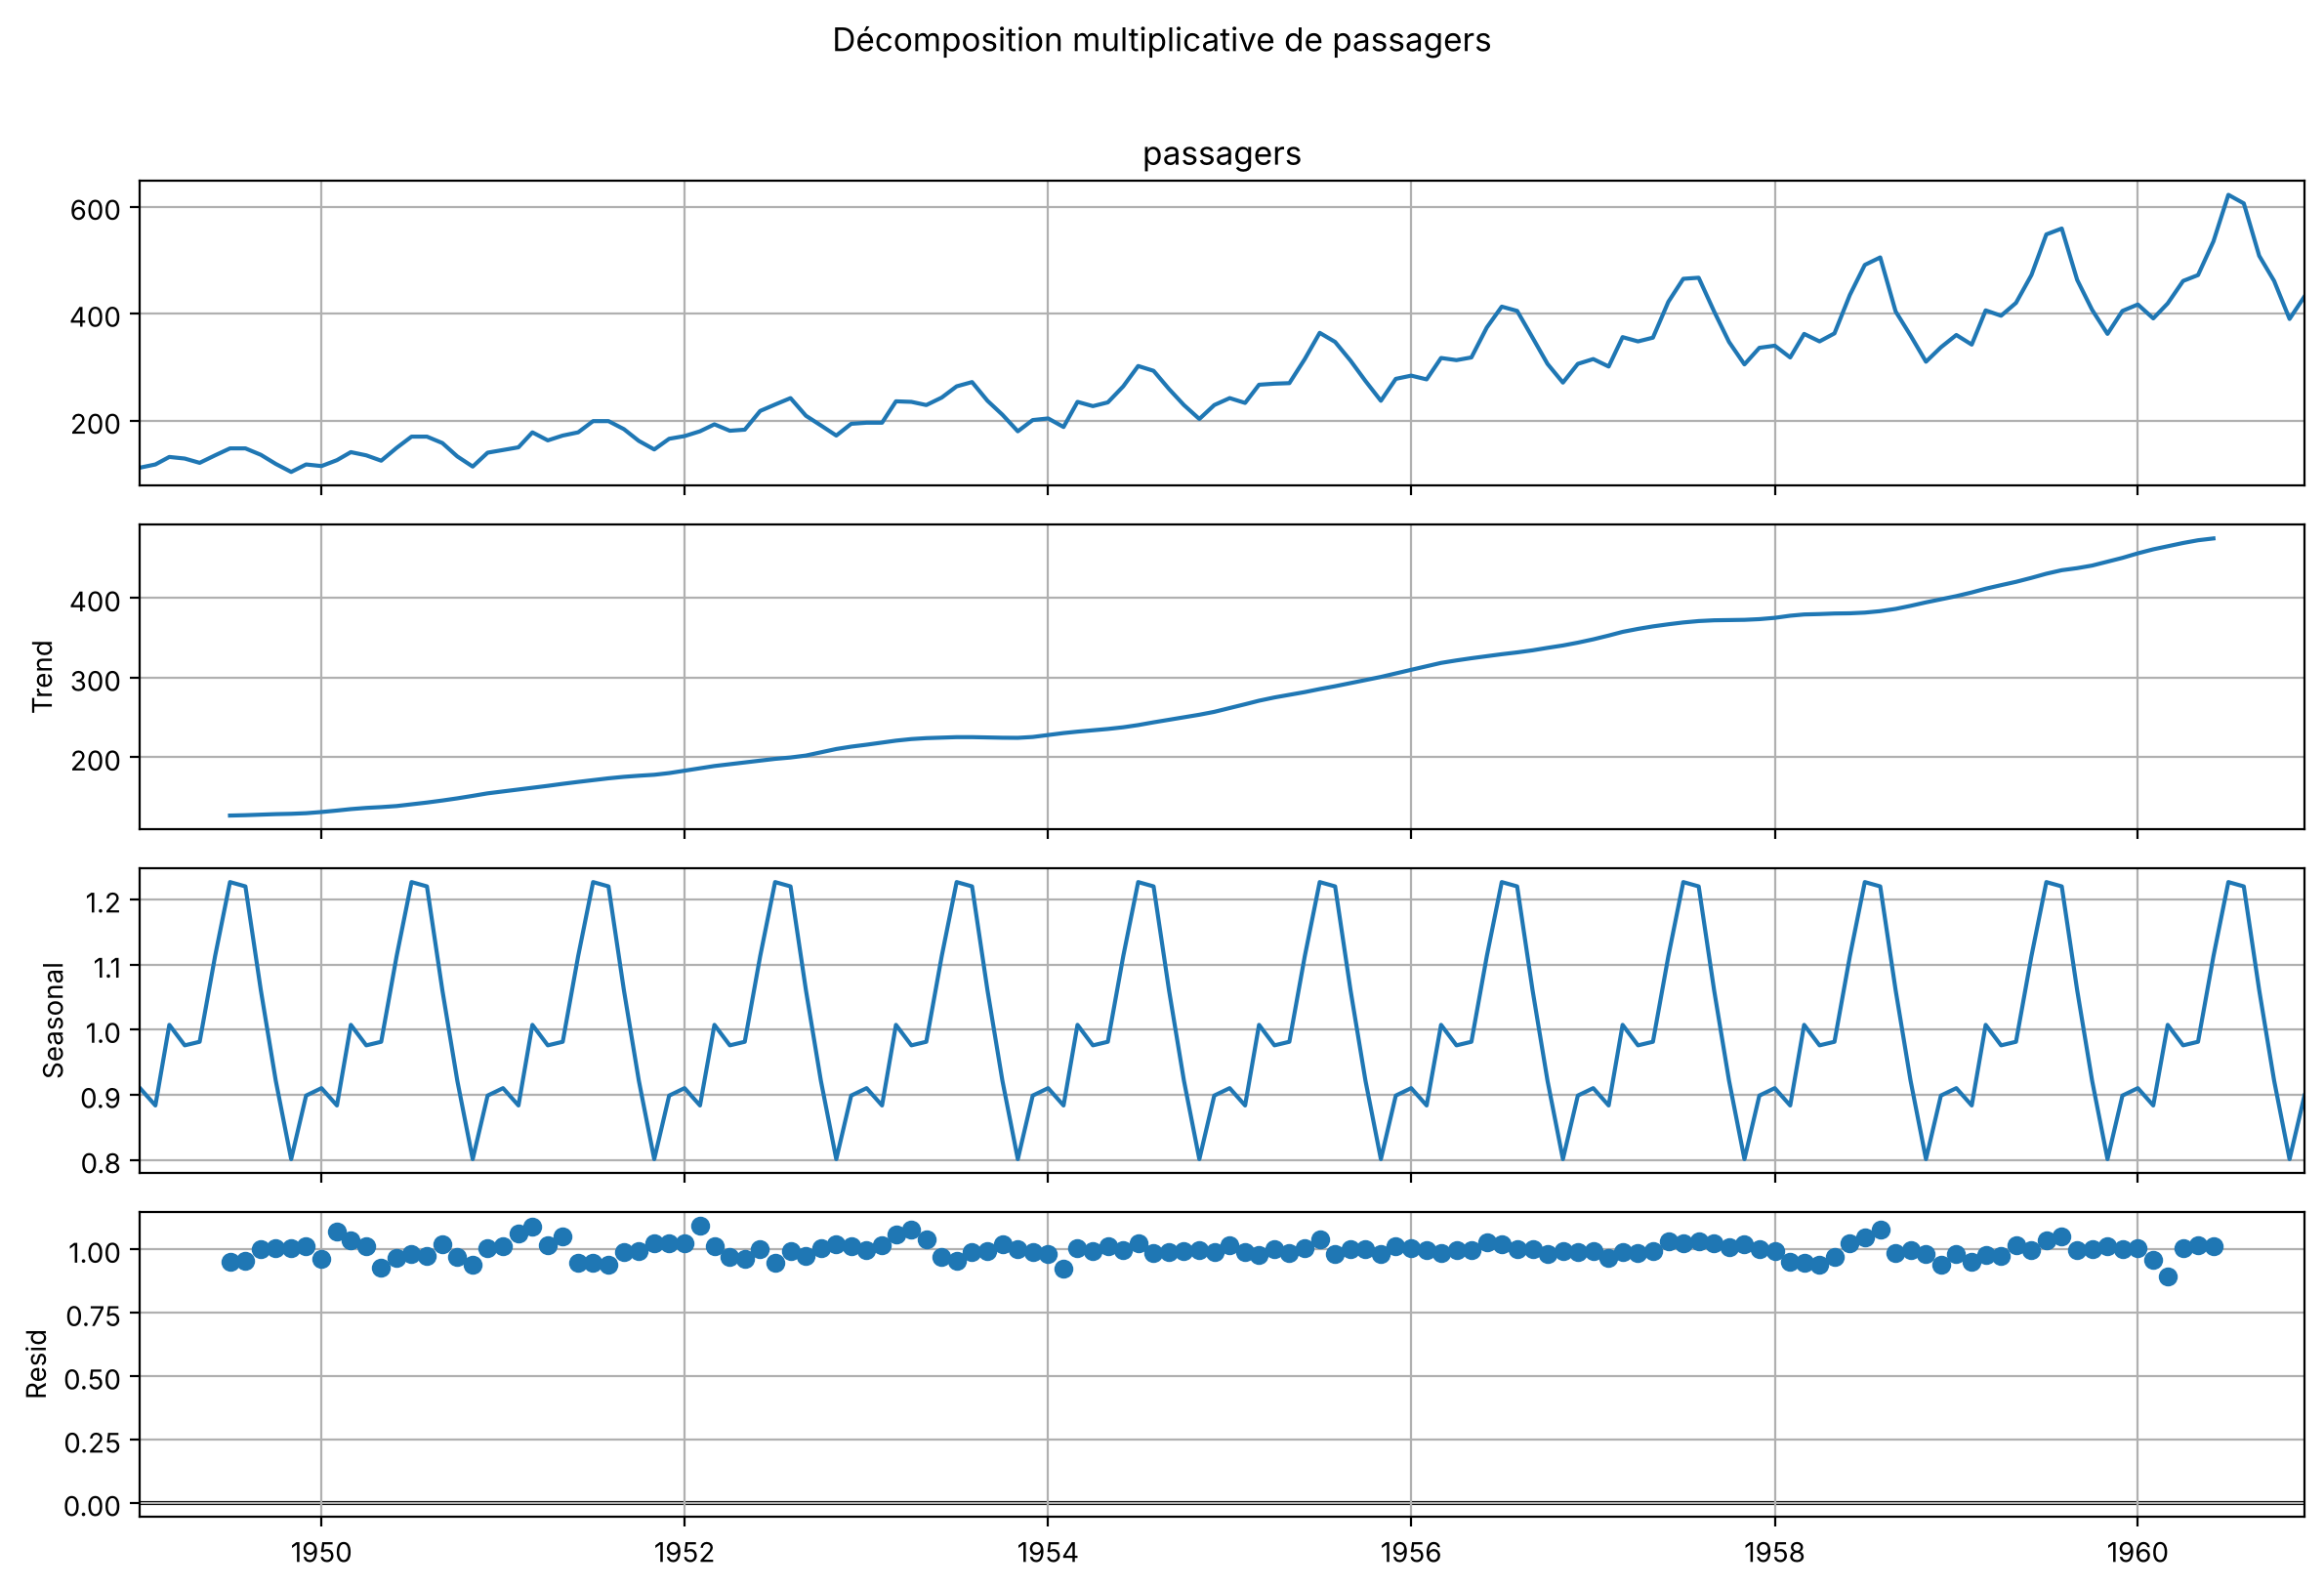

In [ ]:
decomp = air.decomposition(periode=12, modele="multiplicative")

**Lecture :** *Trend* monte régulièrement ; *Seasonal* oscille autour de 1 (≈ +20 % en juillet-août) ; *Resid* doit ressembler à du bruit autour de 1.

--- Stationnarité de 'passagers' ---
ADF  : stat = 0.815 | p-value = 0.9919 -> NON stationnaire
KPSS : stat = 1.651 | p-value = 0.0100 -> NON stationnaire
=> Les deux tests concluent : série NON stationnaire


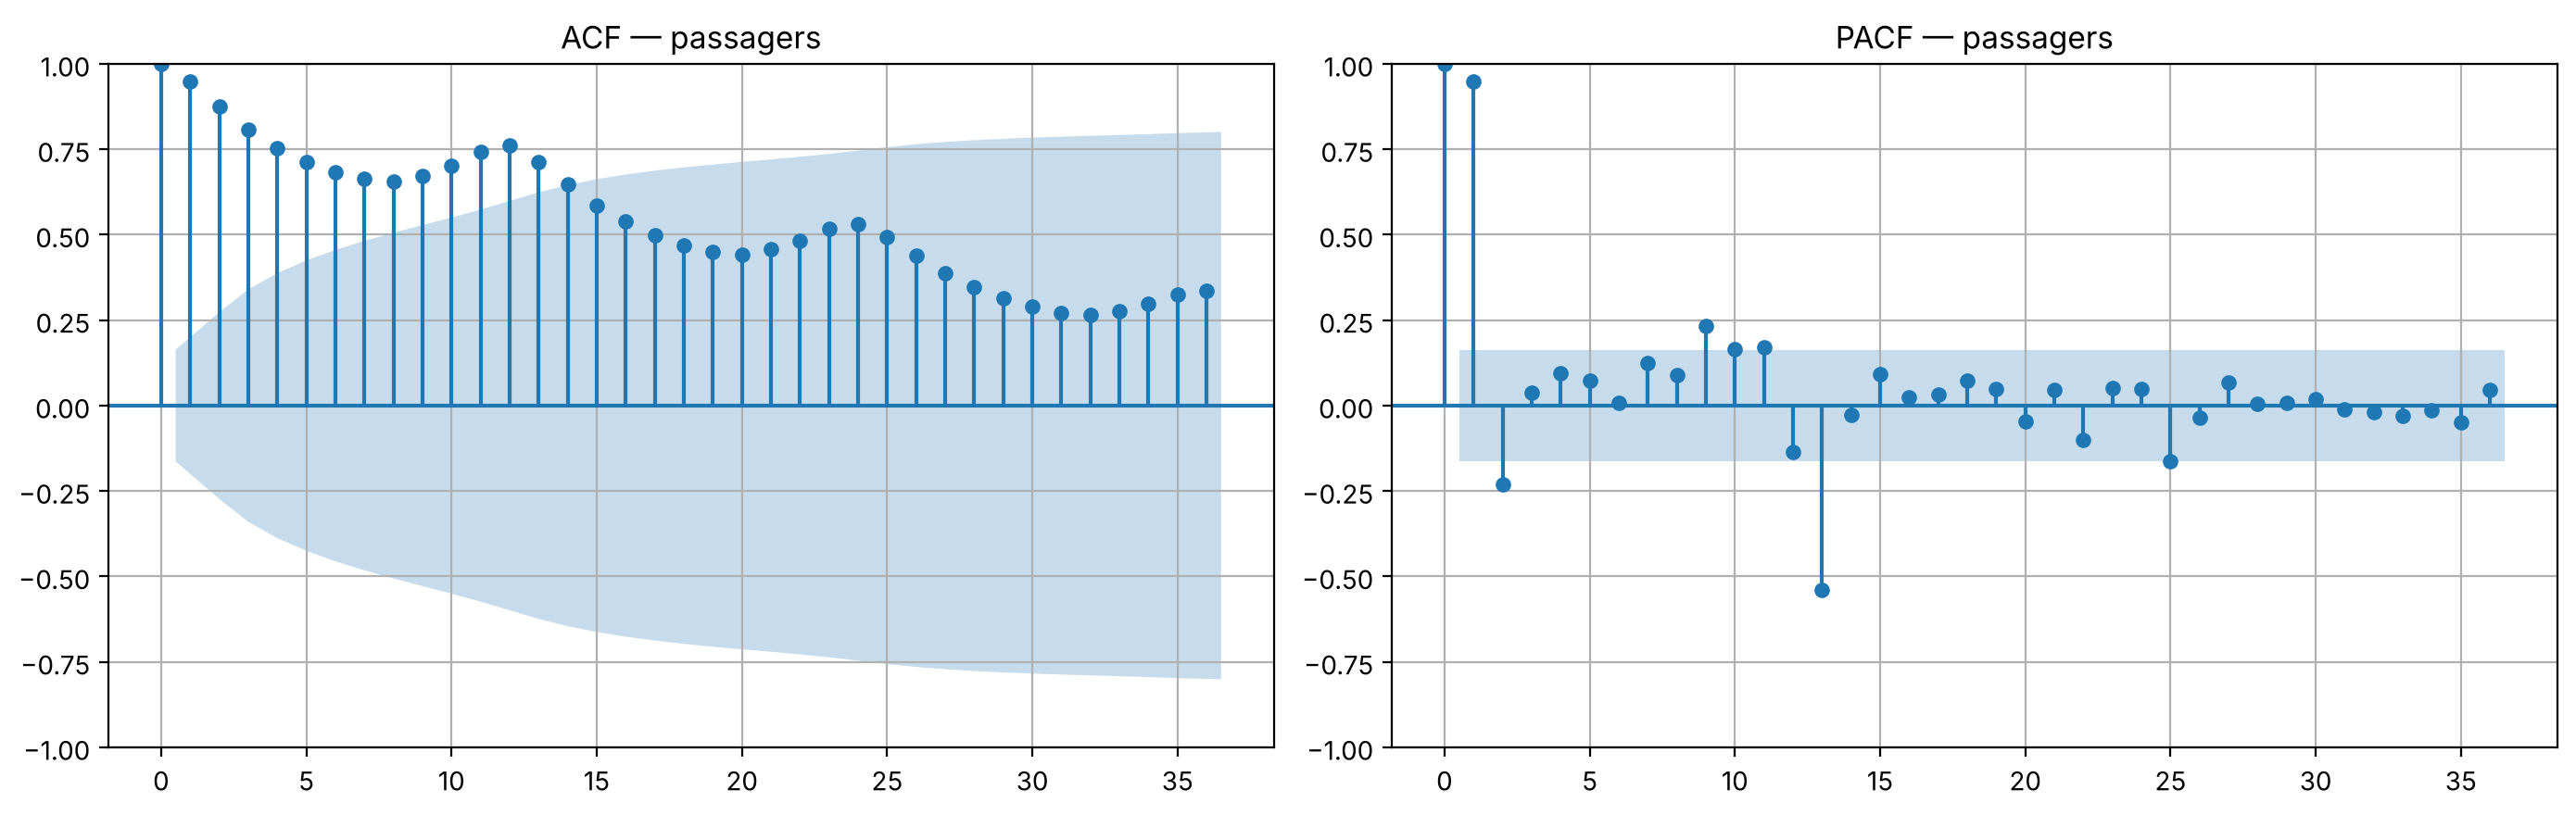

In [ ]:
air.stationnarite()
air.courbe_ACF_PACF(lags=36)

**Lecture :** l'ACF décroît très lentement avec des bosses à 12, 24, 36 → tendance + saisonnalité → la série brute **n'est pas stationnaire**.

Lambda optimal : 0.148  (proche de 0 => le log suffit)


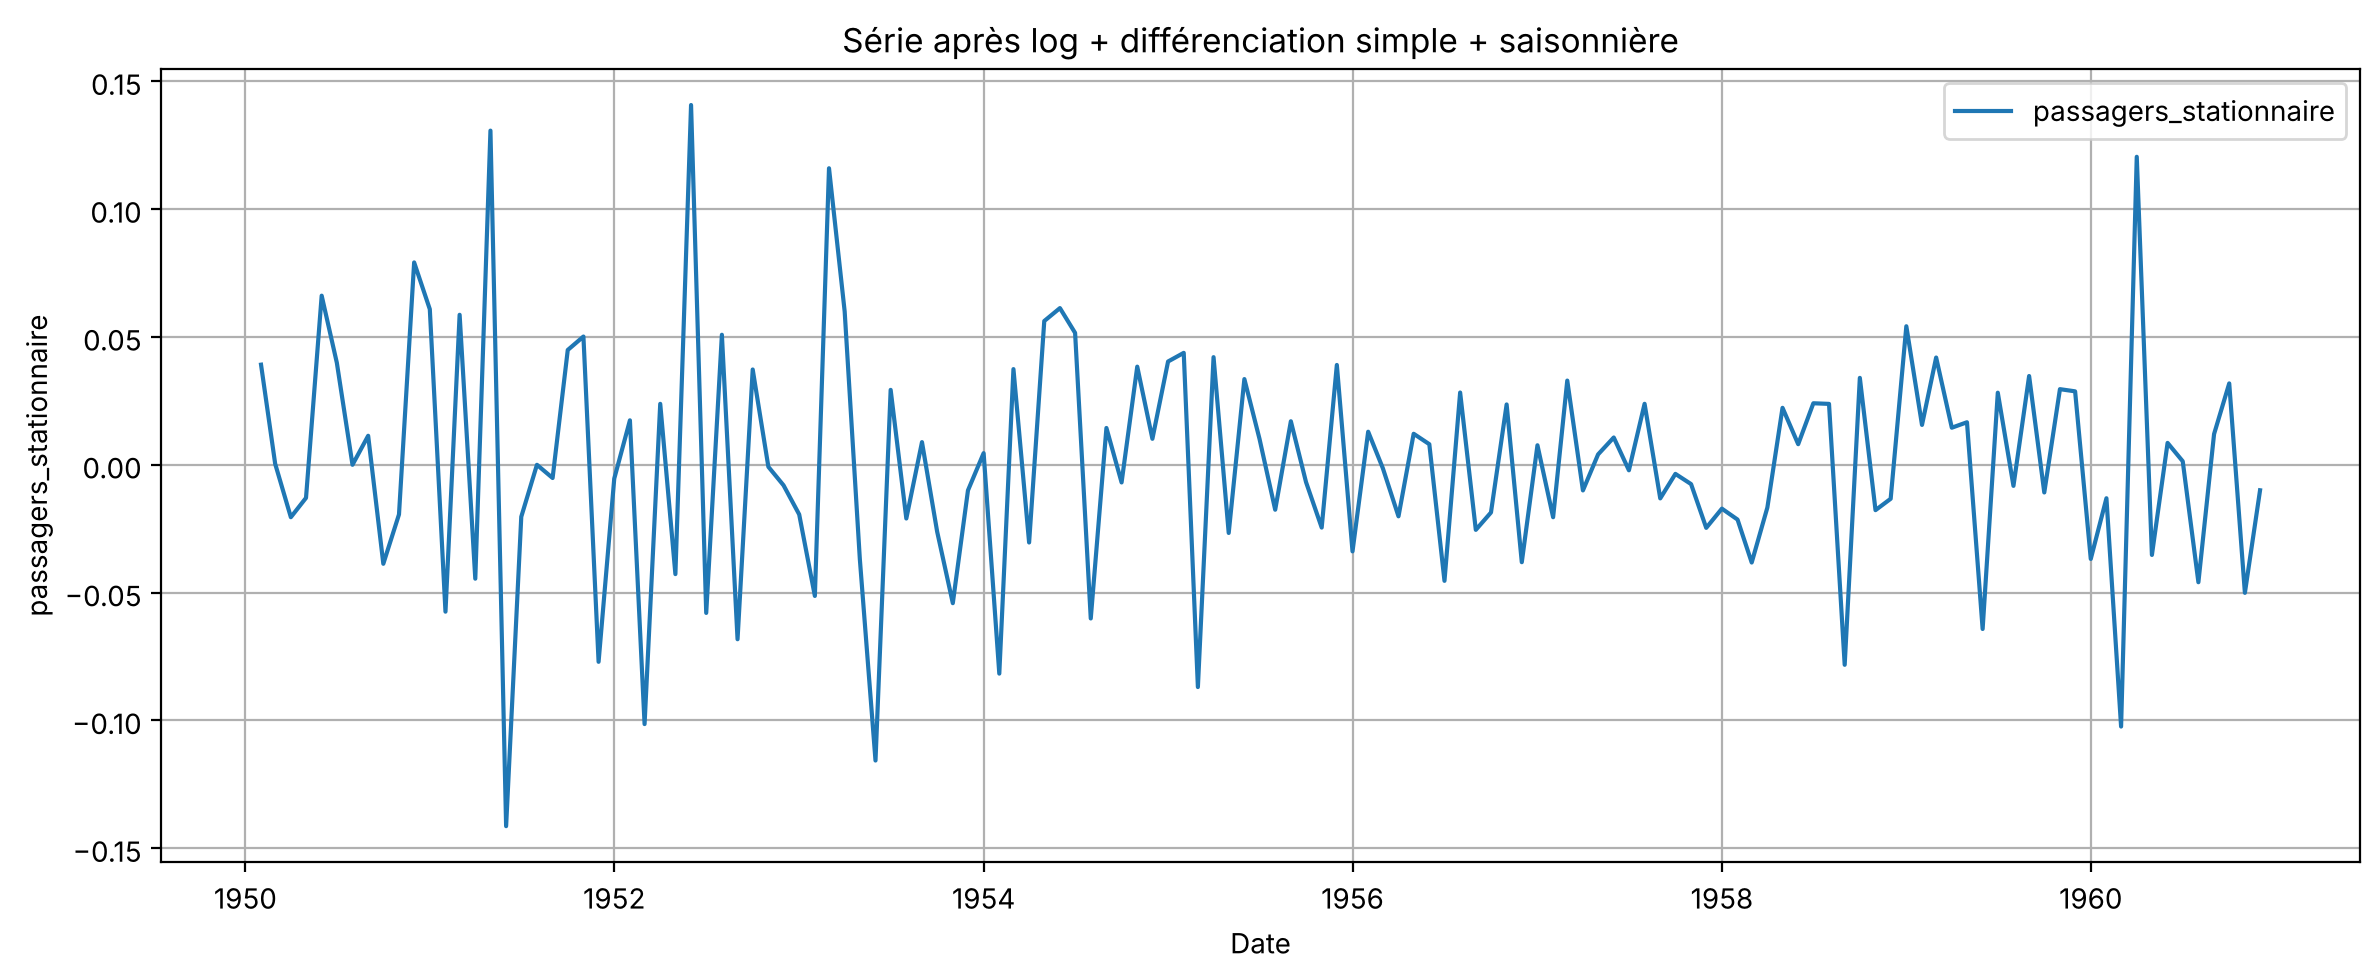

--- Stationnarité de 'passagers_stationnaire' ---
ADF  : stat = -4.443 | p-value = 0.0002 -> stationnaire
KPSS : stat = 0.073 | p-value = 0.1000 -> stationnaire
=> Les deux tests concluent : série STATIONNAIRE


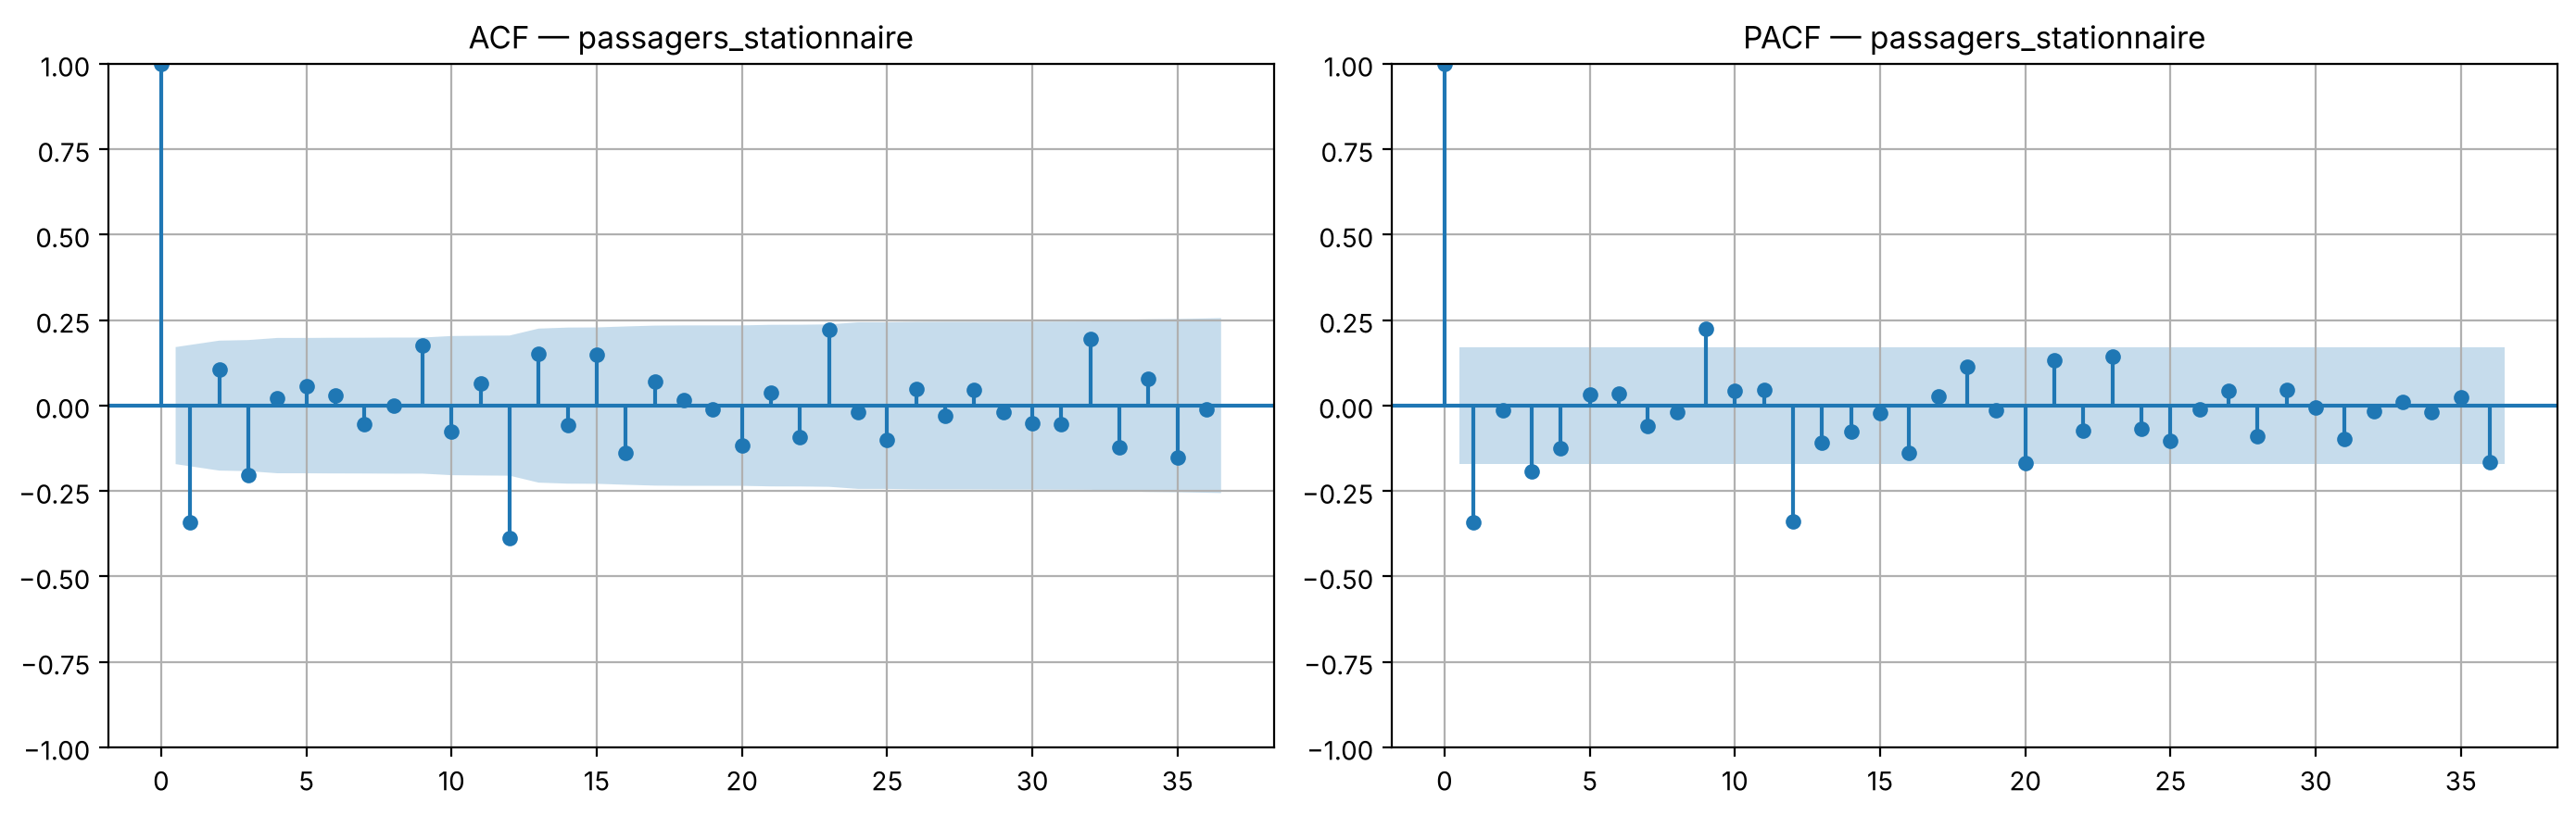

In [ ]:
_, lam = air.boxcox()   # lambda proche de 0 => la transformation log est justifiée
col_stat = air.rendre_stationnaire(periode=12, log=True)
air.courbe_ACF_PACF(lags=36, colonne=col_stat)   # CORRECTION : ACF de la série stationnaire

### Identification du modèle

Sur la série stationnaire (log + d=1 + D=1) :
- **ACF** : pic significatif au retard **1** puis coupure → **MA(1)** non saisonnier (q = 1) ; pic au retard **12** → **MA(1) saisonnier** (Q = 1).
- **PACF** : décroissance progressive aux retards 1, 12, 24 → cohérent avec une structure MA.

Modèle candidat : **SARIMA(0,1,1)(0,1,1)[12]** sur log(passagers) — le célèbre « airline model ».

In [ ]:
air.decouper(n_test=24)
manuel = air.entrainement_sarimax(order=(0, 1, 1), seasonal_order=(0, 1, 1, 12))
auto = air.entrainement_autoarima()

Entraînement : 1949-01-01 -> 1958-12-01 (120 obs.)
Test         : 1959-01-01 -> 1960-12-01 (24 obs.)


SARIMA(0, 1, 1)(0, 1, 1, 12) entraîné | AIC = -389.01 | BIC = -380.99


Meilleur modèle trouvé par auto_arima : (2, 0, 0) (0, 1, 1, 12)


auto (2, 0, 0)(0, 1, 1, 12) entraîné | AIC = -388.73 | BIC = -378.00


## 4. Validation du modèle

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.3425      0.087     -3.923      0.000      -0.514      -0.171
ma.S.L12      -0.5407      0.105     -5.157      0.000      -0.746      -0.335
sigma2         0.0014      0.000      7.865      0.000       0.001       0.002


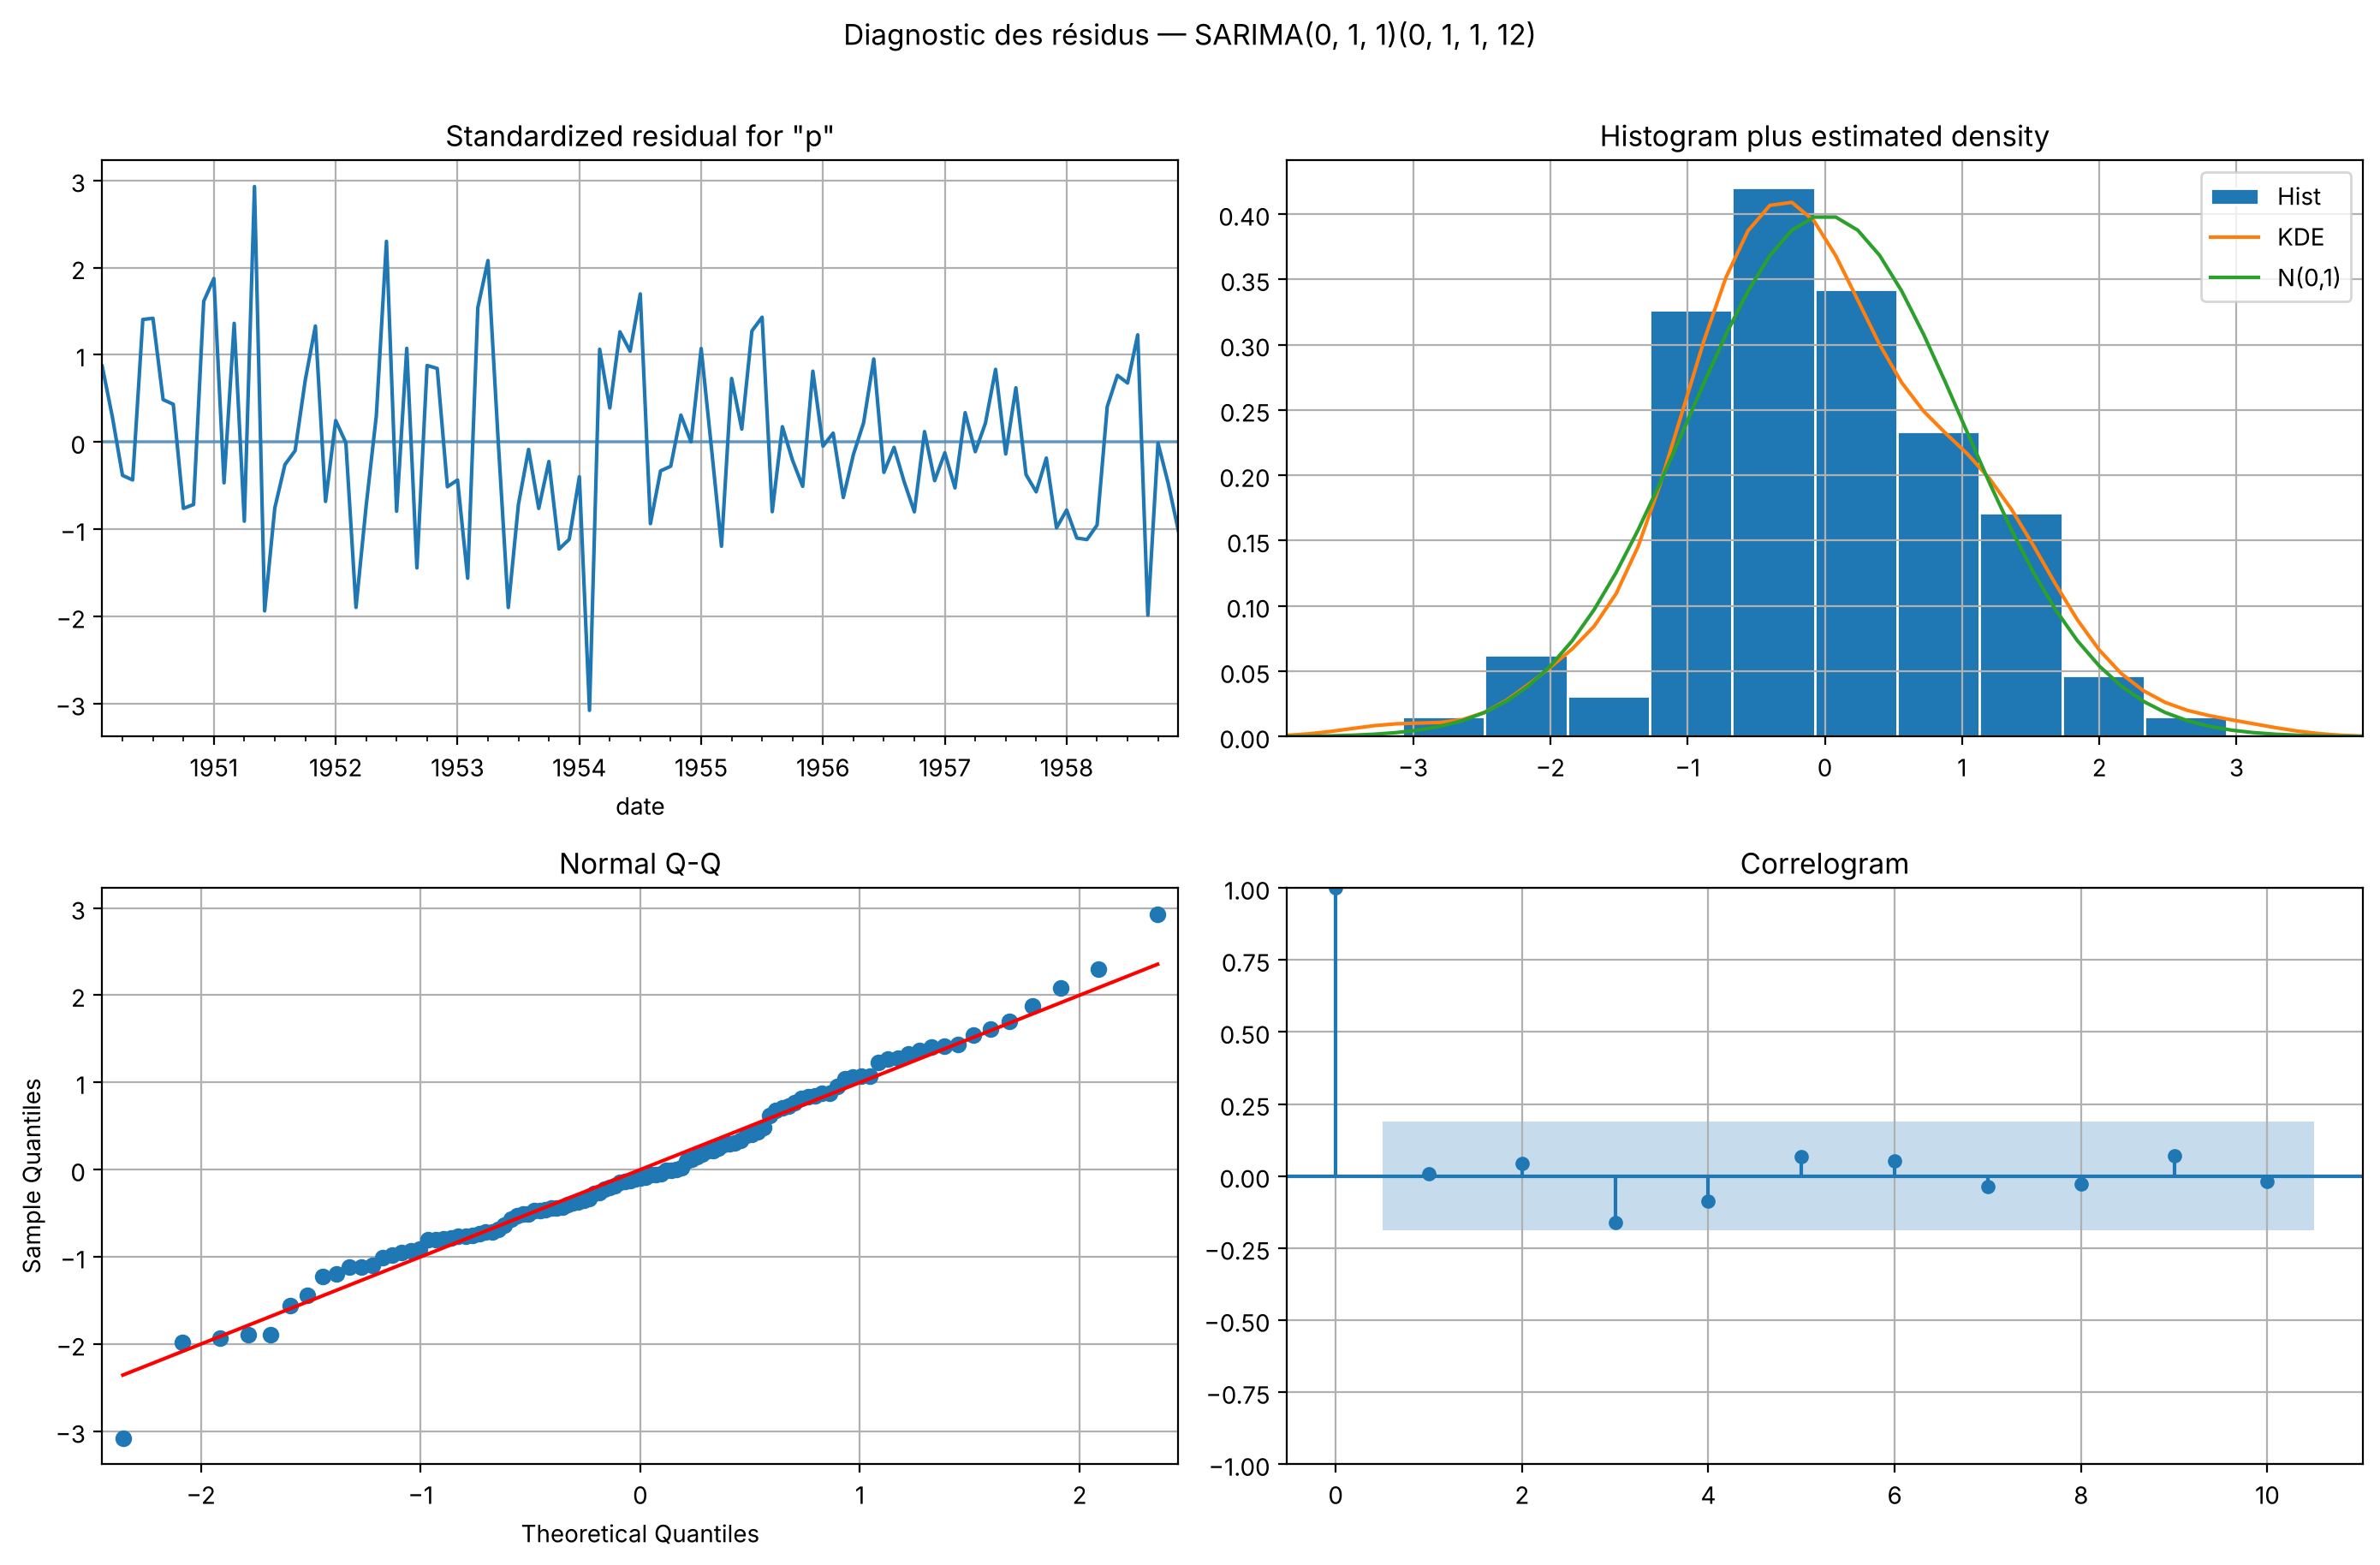

In [ ]:
air.diagnostic(manuel)

**Lecture des 4 panneaux :** résidus centrés sur 0 sans structure ; histogramme proche de N(0,1) ; points du Q-Q alignés sur la droite ; corrélogramme sans bâton hors de la zone bleue → **bruit blanc**.

In [ ]:
air.tests_parametriques(manuel);
print()
air.tests_parametriques(auto);

=============== TESTS — SARIMA(0, 1, 1)(0, 1, 1, 12) ===============
1. Significativité des coefficients (H0 : coef = 0, on veut p < 0.05)
            coef       z  p-value significatif
ma.L1    -0.3425 -3.9228   0.0001          oui
ma.S.L12 -0.5407 -5.1569   0.0000          oui 

2. Moyenne des résidus = 0 (Student)   p = 0.9394  OK
3. Bruit blanc (Ljung-Box, 12 retards)  p = 0.9124  OK
4. Normalité (Shapiro / Jarque-Bera)   p = 0.4868 / 0.5784  OK
5. Variance constante (ARCH d'Engle)   p = 0.2693  OK

=============== TESTS — auto (2, 0, 0)(0, 1, 1, 12) ===============
1. Significativité des coefficients (H0 : coef = 0, on veut p < 0.05)
            coef       z  p-value significatif
ar.L1     0.6827  8.6788   0.0000          oui
ar.L2     0.3073  3.8044   0.0001          oui
ma.S.L12 -0.5397 -5.1183   0.0000          oui 

2. Moyenne des résidus = 0 (Student)   p = 0.3419  OK
3. Bruit blanc (Ljung-Box, 12 retards)  p = 0.8104  OK
4. Normalité (Shapiro / Jarque-Bera)   p = 0.6020 / 0.

## 5. Évaluation sur le jeu de test (24 derniers mois)

,AIC,MAE,RMSE,MAPE (%)
modèle,,,,
"SARIMA(0, 1, 1)(0, 1, 1, 12)",-389.01,39.44,43.17,8.51
"auto (2, 0, 0)(0, 1, 1, 12)",-388.73,48.28,52.72,10.42


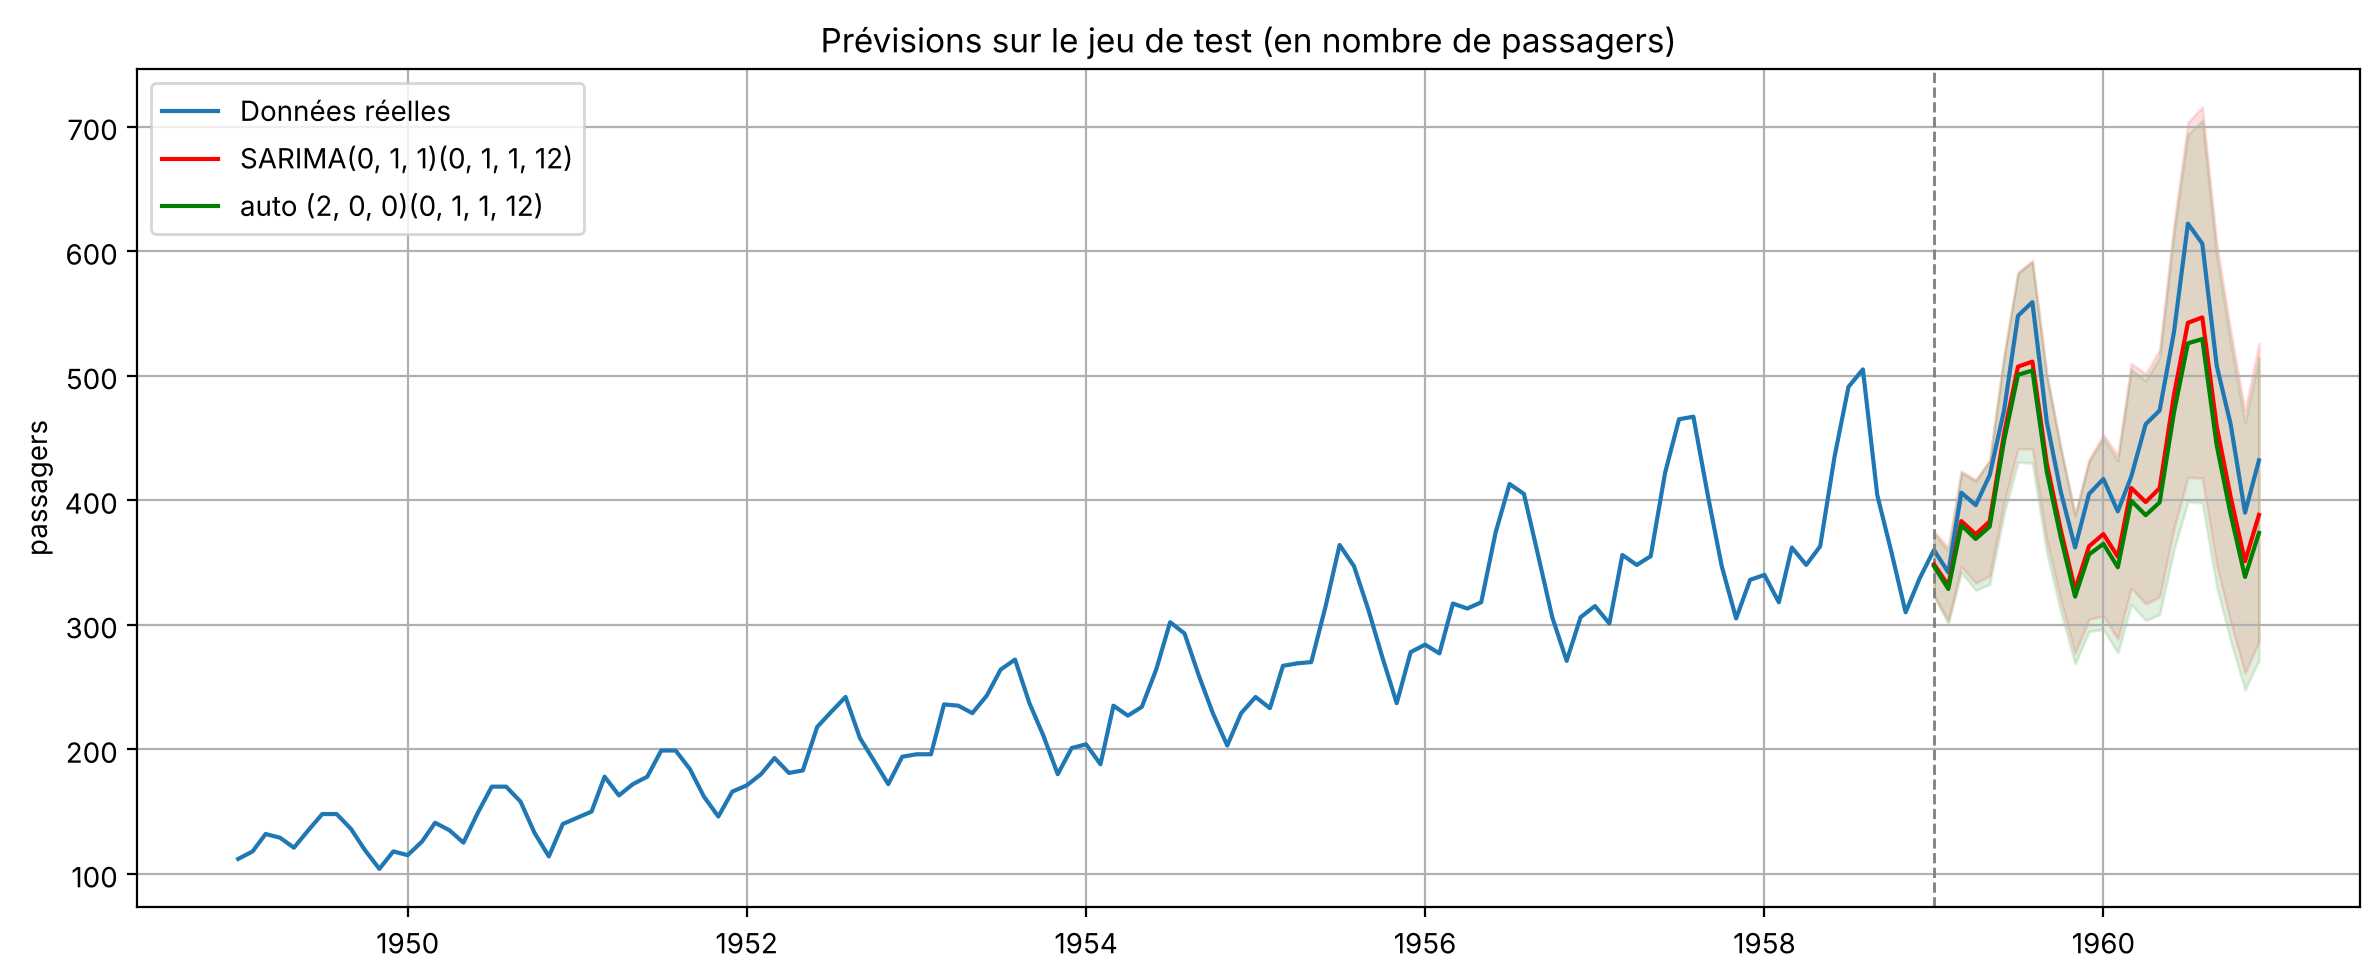

In [ ]:
air.prediction(manuel)
air.prediction(auto)
display(air.evaluation())
air.visualisation_prediction(titre="Prévisions sur le jeu de test (en nombre de passagers)")

**Lecture :** plus la **MAPE** est faible, meilleur est le modèle (< 10 % = bonne prévision). La zone colorée est l'intervalle de confiance à 95 % : elle s'élargit avec l'horizon.

## 6. Prévision finale : réentraînement sur toutes les données, 24 mois dans le futur

final entraîné | AIC = -483.39 | BIC = -474.77


,prevision,borne_inf,borne_sup
1961-01-01,450.0,419.0,484.0
1961-02-01,426.0,391.0,463.0
1961-03-01,479.0,436.0,526.0
1961-04-01,492.0,444.0,546.0
1961-05-01,509.0,455.0,569.0
1961-06-01,583.0,517.0,658.0
1961-07-01,670.0,590.0,761.0
1961-08-01,667.0,583.0,763.0
1961-09-01,558.0,485.0,643.0
1961-10-01,497.0,429.0,576.0


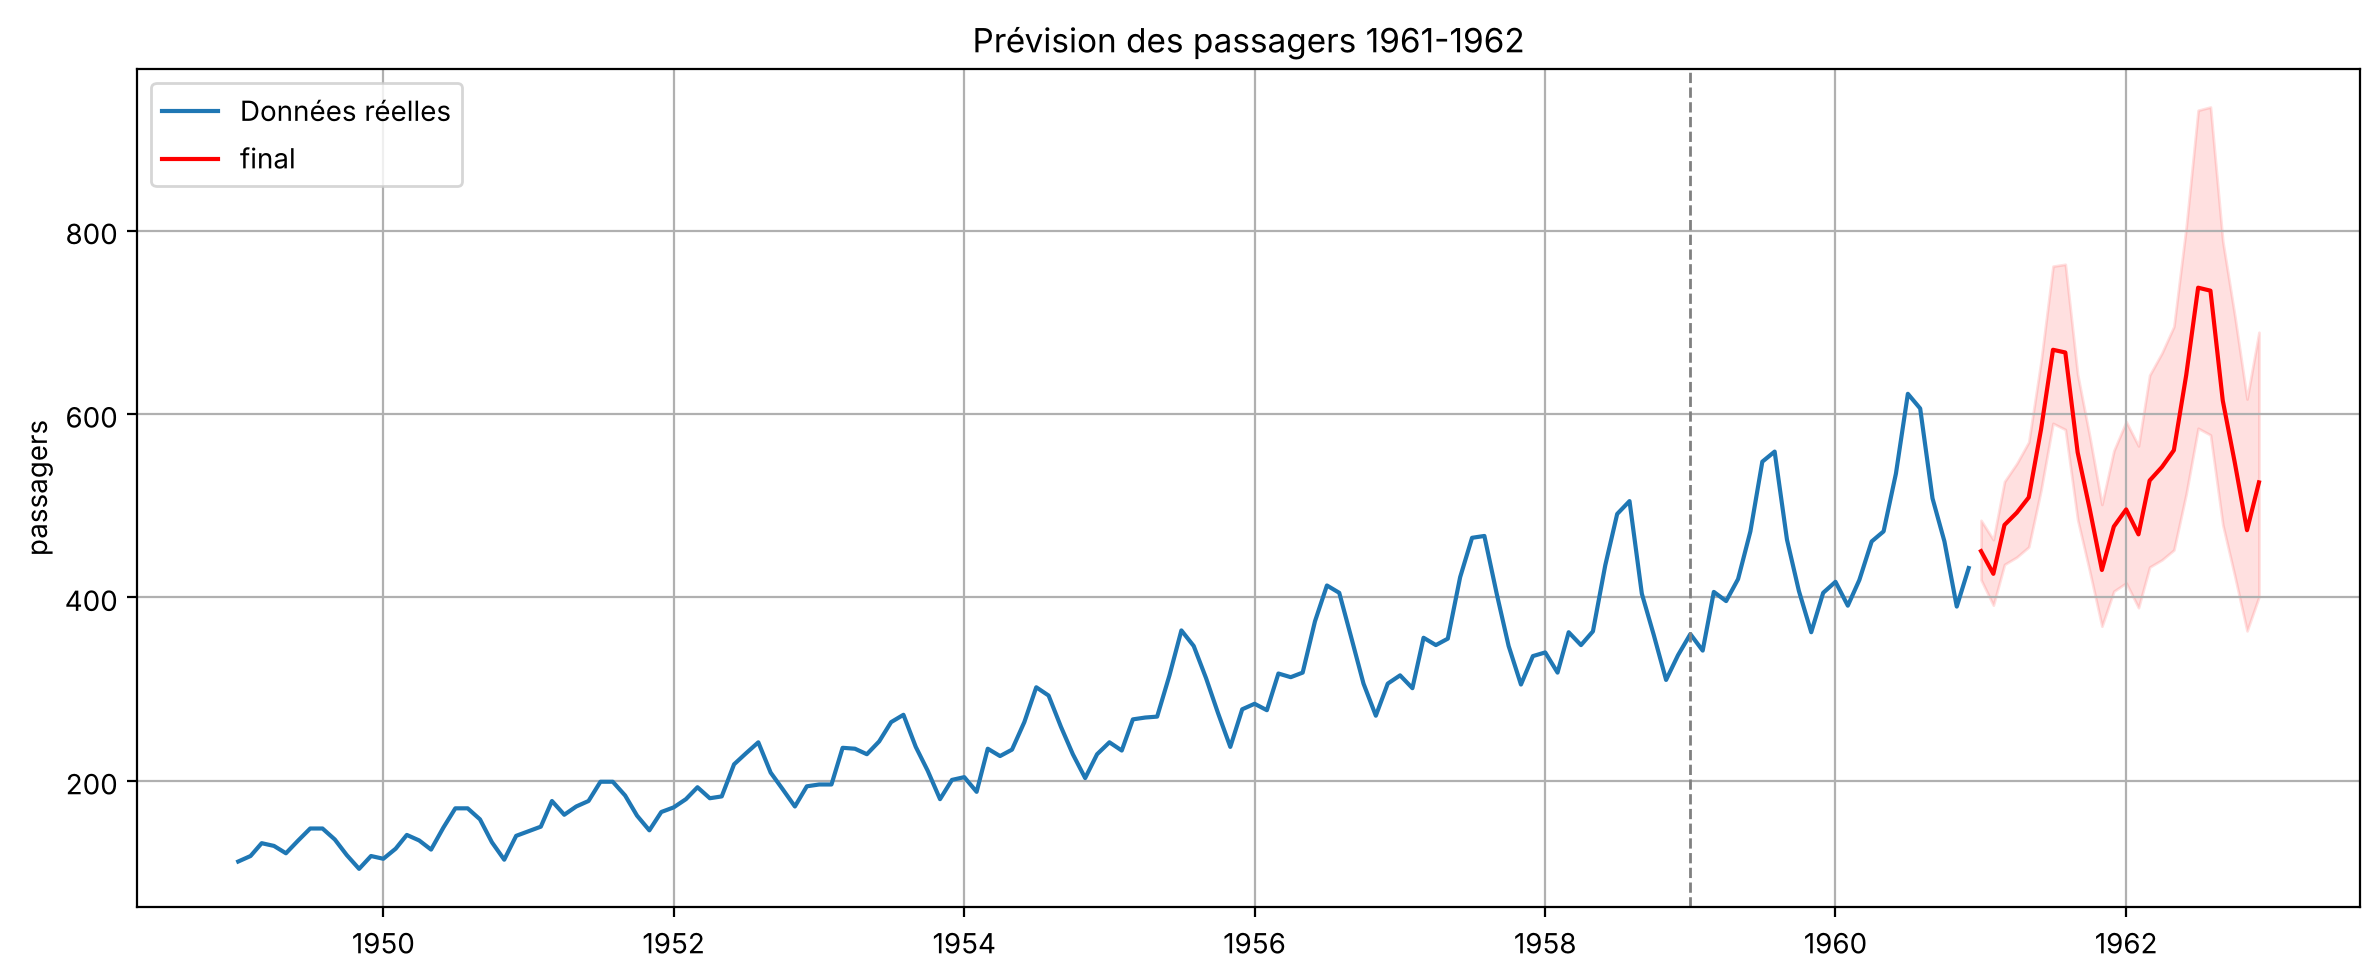

In [ ]:
final = air.entrainement_sarimax((0, 1, 1), (0, 1, 1, 12), nom="final", serie=air.donnee["passagers"])
prev_futur = air.prediction("final", horizon=24)
display(prev_futur.head(12).round(0))
air.visualisation_prediction(noms=["final"], titre="Prévision des passagers 1961-1962")

## 7. Même démarche sur vos données AQI

Déposez `aqi_mensuel.csv` (colonnes `date`, `aqi`) dans `/content/` puis exécutez la cellule. Adaptez les ordres du modèle après lecture de l'ACF/PACF.

In [ ]:
import os
chemin = "/content/aqi_mensuel.csv"

if os.path.exists(chemin):
    aqi = Sarimax_model(pd.read_csv(chemin), colonne="aqi", date="date", s=12,
                        log=True)   # log=False si l'amplitude saisonnière est constante
    aqi.description()
    aqi.traitement_valeurs_manquantes("interpolate")
    aqi.visualisation()
    aqi.decomposition(periode=12, modele="additive")
    aqi.stationnarite()
    aqi.courbe_ACF_PACF(lags=36)
    col = aqi.rendre_stationnaire(periode=12, log=aqi.log)
    aqi.courbe_ACF_PACF(lags=36, colonne=col)

    aqi.decouper(n_test=12)
    m_auto = aqi.entrainement_autoarima()
    aqi.diagnostic(m_auto)
    aqi.tests_parametriques(m_auto)
    aqi.prediction(m_auto)
    display(aqi.evaluation())
    aqi.visualisation_prediction()
else:
    print("Fichier AQI introuvable : section ignorée.")

Fichier AQI introuvable : section ignorée.


## Aide-mémoire d'interprétation

| Graphe / test | Ce qu'on regarde | Bon signe |
|---|---|---|
| Série brute | tendance, saisonnalité, variance | — (sert à choisir log / différenciation) |
| Décomposition | trend, seasonal, resid | résidus sans structure |
| ADF | H0 : non stationnaire | p < 0,05 |
| KPSS | H0 : stationnaire | p > 0,05 |
| ACF | coupure après q → MA(q) ; pics à 12, 24 → saisonnier | décroissance rapide après différenciation |
| PACF | coupure après p → AR(p) | — |
| Coefficients | H0 : coef = 0 | p < 0,05 |
| Ljung-Box, normalité, ARCH | résidus = bruit blanc | p > 0,05 |
| MAPE | erreur moyenne en % | < 10 % |